# RetailPulse — Customer RFM Segmentation

## Objective
Segment retail customers based on their purchasing behaviour
using Recency, Frequency, and Monetary analysis.

## RFM Metrics
- Recency: Days since the customer's last purchase.
- Frequency: Number of unique invoices.
- Monetary: Total customer revenue.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/processed/cleaned_transactions.csv")

sales = pd.read_csv(DATA_PATH)

sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

print("Dataset shape:", sales.shape)

sales.head()

Dataset shape: (524878, 9)


C:\Users\Swami-Anand\AppData\Local\Temp\ipykernel_28796\317429861.py:5: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(DATA_PATH)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
rfm_data = sales.dropna(
    subset=["CustomerID"]
).copy()

rfm_data["CustomerID"] = (
    rfm_data["CustomerID"].astype(str)
)

print("Total sales records:", len(sales))
print("Records with CustomerID:", len(rfm_data))
print("Unique customers:", rfm_data["CustomerID"].nunique())

Total sales records: 524878
Records with CustomerID: 392692
Unique customers: 4338


In [4]:
reference_date = (
    rfm_data["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    rfm_data.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate",
                 lambda x: (reference_date - x.max()).days),

        Frequency=("InvoiceNo", "nunique"),

        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [5]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,2,7,4310.00,5,5,5,555
2,12348.0,75,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112


In [6]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] >= 4:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    else:
        return "Regular Customers"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346.0,326,1,77183.60,1,1,5,115,Regular Customers
1,12347.0,2,7,4310.00,5,5,5,555,Champions
2,12348.0,75,4,1797.24,2,4,4,244,At Risk
3,12349.0,19,1,1757.55,4,1,4,414,Recent Customers
4,12350.0,310,1,334.40,1,1,2,112,Regular Customers


In [7]:
segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customers=("CustomerID", "count"),
        Revenue=("Monetary", "sum"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean")
    )
    .reset_index()
)

segment_summary = segment_summary.sort_values(
    "Revenue",
    ascending=False
)

segment_summary.round(2)

,Customer_Segment,Customers,Revenue,Average_Recency,Average_Frequency
1,Champions,1122,5859932.94,12.99,10.05
2,Loyal Customers,820,1378713.51,37.23,3.69
0,At Risk,661,823912.44,150.64,3.41
4,Regular Customers,1425,682410.56,176.24,1.12
3,Recent Customers,310,142239.44,18.10,1.25


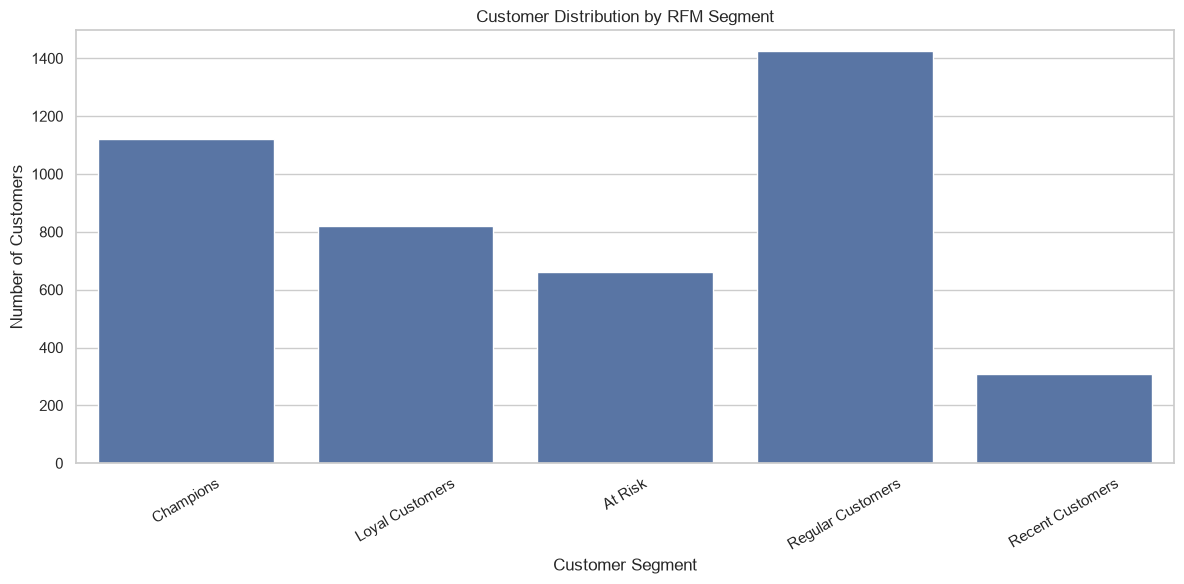

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="Customer_Segment",
    y="Customers"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

rfm.to_csv(
    REPORT_DIR / "customer_rfm_analysis.csv",
    index=False
)

segment_summary.to_csv(
    REPORT_DIR / "customer_segment_summary.csv",
    index=False
)

print("RFM analysis reports exported successfully!")

RFM analysis reports exported successfully!


In [10]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346.0,326,1,77183.60,1,1,5,115,Regular Customers
1,12347.0,2,7,4310.00,5,5,5,555,Champions
2,12348.0,75,4,1797.24,2,4,4,244,At Risk
3,12349.0,19,1,1757.55,4,1,4,414,Recent Customers
4,12350.0,310,1,334.40,1,1,2,112,Regular Customers
5,12352.0,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353.0,204,1,89.00,1,1,1,111,Regular Customers
7,12354.0,232,1,1079.40,1,1,4,114,Regular Customers
8,12355.0,214,1,459.40,1,1,2,112,Regular Customers
9,12356.0,23,3,2811.43,4,3,5,435,Loyal Customers


In [11]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] >= 4:
        return "Recent Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    else:
        return "Regular Customers"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

rfm[[
    "CustomerID",
    "Recency",
    "Frequency",
    "Monetary",
    "RFM_Score",
    "Customer_Segment"
]].head(15)

,CustomerID,Recency,Frequency,Monetary,RFM_Score,Customer_Segment
0,12346.0,326,1,77183.60,115,Regular Customers
1,12347.0,2,7,4310.00,555,Champions
2,12348.0,75,4,1797.24,244,At Risk
3,12349.0,19,1,1757.55,414,Recent Customers
4,12350.0,310,1,334.40,112,Regular Customers
5,12352.0,36,8,2506.04,355,Loyal Customers
6,12353.0,204,1,89.00,111,Regular Customers
7,12354.0,232,1,1079.40,114,Regular Customers
8,12355.0,214,1,459.40,112,Regular Customers
9,12356.0,23,3,2811.43,435,Loyal Customers


In [12]:
segment_summary = (
    rfm.groupby("Customer_Segment", observed=True)
    .agg(
        Customers=("CustomerID", "count"),
        Revenue=("Monetary", "sum"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean")
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
    * 100
)

segment_summary.round(2)

,Customer_Segment,Customers,Revenue,Average_Recency,Average_Frequency,Customer_Percentage
0,At Risk,661,823912.44,150.64,3.41,15.24
1,Champions,1122,5859932.94,12.99,10.05,25.86
2,Loyal Customers,820,1378713.51,37.23,3.69,18.90
3,Recent Customers,310,142239.44,18.10,1.25,7.15
4,Regular Customers,1425,682410.56,176.24,1.12,32.85


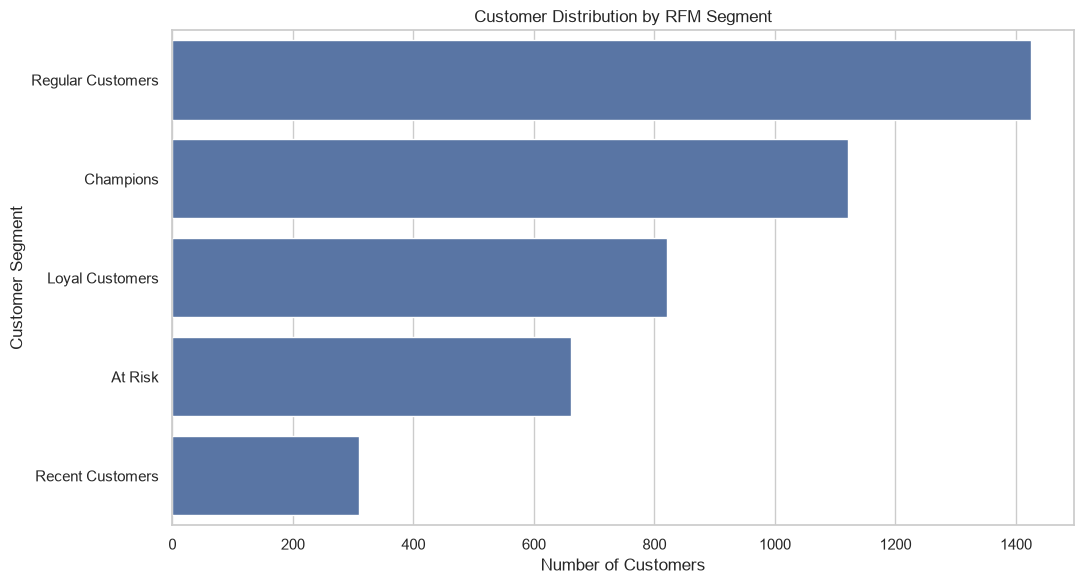

In [13]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_summary.sort_values("Customers", ascending=False),
    x="Customers",
    y="Customer_Segment"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

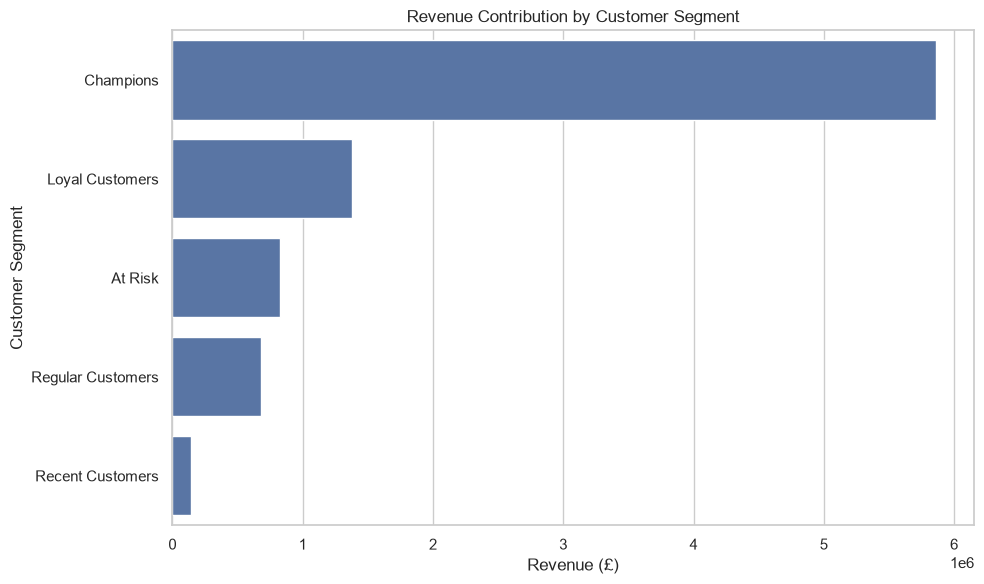

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary.sort_values("Revenue", ascending=False),
    x="Revenue",
    y="Customer_Segment"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

rfm.to_csv(
    REPORT_DIR / "customer_rfm_analysis.csv",
    index=False
)

segment_summary.to_csv(
    REPORT_DIR / "customer_segment_summary.csv",
    index=False
)

print("RFM reports exported successfully!")

RFM reports exported successfully!


# Business Insights and Conclusion

## Key Analysis
- Customers are segmented based on Recency, Frequency and Monetary value.
- Champions represent recently active, frequent purchasers.
- At Risk customers may require targeted retention campaigns.
- Revenue contribution helps identify valuable customer segments.

## Business Recommendations
1. Reward Champions through loyalty programs.
2. Develop retention campaigns for At Risk customers.
3. Encourage Recent Customers to make repeat purchases.
4. Monitor customer spending patterns over time.

## Conclusion
RFM analysis provides a structured approach to customer
segmentation and helps businesses make customer-focused
marketing and retention decisions.